In [1]:
!pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 10.8 MB/s eta 0:00:00a 0:00:01


In [2]:
import os
import cv2
import math
import shutil
import warnings
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from PIL import Image

from scipy.signal import butter, filtfilt
from scipy.spatial.distance import cdist

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif
)

from sklearn.metrics import (
    roc_curve,
    auc
)

import neurokit2 as nk
import pywt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    TensorDataset,
    random_split
)

import torchvision.transforms as transforms

from torchsummary import summary
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
import kagglehub

path = kagglehub.dataset_download("souvickroy29/heart-beat")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/souvickroy29/heart-beat


In [4]:
src_root = "/kaggle/input/datasets/souvickroy29/heart-beat/Heartprint"
dst_root = "session_1"

target_sessions = ["Session-1"]

subjects = sorted(
    d for d in os.listdir(os.path.join(src_root, "Session-1"))
    if os.path.isdir(os.path.join(src_root, "Session-1", d))
)

label_map = {subject: idx for idx, subject in enumerate(subjects)}

for session in target_sessions:

    session_path = os.path.join(src_root, session)

    if not os.path.exists(session_path):
        continue

    for subject in os.listdir(session_path):

        subject_path = os.path.join(session_path, subject)

        if not os.path.isdir(subject_path):
            continue

        label = label_map[subject]

        dst_label_dir = os.path.join(dst_root, str(label))
        os.makedirs(dst_label_dir, exist_ok=True)

        for file_name in os.listdir(subject_path):

            src_file = os.path.join(subject_path, file_name)

            if not os.path.isfile(src_file):
                continue

            new_name = f"{session}_{file_name}"

            dst_file = os.path.join(dst_label_dir, new_name)

            shutil.copy2(src_file, dst_file)   

In [5]:
src_root = "/kaggle/input/datasets/souvickroy29/heart-beat/Heartprint"
dst_root = "session_2"

target_sessions = ["Session-2"]

subjects = sorted(
    d for d in os.listdir(os.path.join(src_root, "Session-2"))
    if os.path.isdir(os.path.join(src_root, "Session-2", d))
)

label_map = {subject: idx for idx, subject in enumerate(subjects)}

for session in target_sessions:

    session_path = os.path.join(src_root, session)

    if not os.path.exists(session_path):
        continue

    for subject in os.listdir(session_path):

        subject_path = os.path.join(session_path, subject)

        if not os.path.isdir(subject_path):
            continue

        label = label_map[subject]

        dst_label_dir = os.path.join(dst_root, str(label))
        os.makedirs(dst_label_dir, exist_ok=True)

        for file_name in os.listdir(subject_path):

            src_file = os.path.join(subject_path, file_name)

            if not os.path.isfile(src_file):
                continue

            new_name = f"{session}_{file_name}"

            dst_file = os.path.join(dst_label_dir, new_name)

            shutil.copy2(src_file, dst_file)  

In [6]:
def bandpass_filter(signal, fs=250, lowcut=0.5, highcut=40):
    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        N=4,
        Wn=[low, high],
        btype='band'
    )

    filtered = filtfilt(b, a, signal)

    return filtered

def detect_rpeaks(ecg, fs=250):

    signals, info = nk.ecg_process(
        ecg,
        sampling_rate=fs
    )

    return info["ECG_R_Peaks"]

def segment_heartbeat(signal, r_peaks, left=100, right=150):

    beats = []

    for r in r_peaks:

        start = r - left
        end = r + right

        if start >= 0 and end < len(signal):

            beat = signal[start:end]

            beats.append(beat)

    return np.array(beats)

In [7]:
def process_ecg_segment(ecg):
    ecg = bandpass_filter(ecg)
    r_peaks = detect_rpeaks(ecg)
    segments = segment_heartbeat(
        ecg,
        r_peaks
    )
    return segments

In [8]:
def generate_cwt_image(signal, img_size):

    wavelets = [
        'mexh',
        'morl',
        'gaus1'
    ]

    scales = np.arange(1,128)

    channels = []

    for wavelet in wavelets:

        coeffs, _ = pywt.cwt(
            signal,
            scales,
            wavelet
        )

        scalogram = np.abs(coeffs)

        scalogram = cv2.resize(
            scalogram,
            (img_size, img_size)
        )

        scalogram = (
            scalogram - scalogram.min()
        ) / (
            scalogram.max() - scalogram.min() + 1e-8
        )

        scalogram = (
            scalogram * 255
        ).astype(np.uint8)

        channels.append(scalogram)

    image = np.stack(
        channels,
        axis=-1
    )

    return image

In [9]:
def create_split_dataset(src_root, dst_root):

    train_root = os.path.join(dst_root, "train")
    val_root   = os.path.join(dst_root, "val")
    test_root  = os.path.join(dst_root, "test")

    os.makedirs(train_root, exist_ok=True)
    os.makedirs(val_root, exist_ok=True)
    os.makedirs(test_root, exist_ok=True)

    for label in sorted(os.listdir(src_root)):

        label_path = os.path.join(src_root, label)

        if not os.path.isdir(label_path):
            continue

        train_label_dir = os.path.join(train_root, label)
        val_label_dir   = os.path.join(val_root, label)
        test_label_dir  = os.path.join(test_root, label)

        os.makedirs(train_label_dir, exist_ok=True)
        os.makedirs(val_label_dir, exist_ok=True)
        os.makedirs(test_label_dir, exist_ok=True)

        for ecg_file in sorted(os.listdir(label_path)):

            ecg_path = os.path.join(label_path, ecg_file)

            if not os.path.isfile(ecg_path):
                continue

            try:

                data = np.loadtxt(ecg_path)

                ecg = data[:3747]

                segments = process_ecg_segment(ecg)

                base_name = os.path.splitext(ecg_file)[0]

                IMG_SIZE = 224

                for seg_idx, segment in enumerate(segments):

                    file_name = (
                        f"{base_name}_seg_{seg_idx:02d}.png"
                    )

                    if seg_idx < 3:

                        save_path = os.path.join(
                            test_label_dir,
                            file_name
                        )

                    elif seg_idx < 6:

                        save_path = os.path.join(
                            val_label_dir,
                            file_name
                        )

                    else:

                        save_path = os.path.join(
                            train_label_dir,
                            file_name
                        )

                    segment = np.array(segment)

                    segment = (
                        segment - np.min(segment)
                    ) / (
                        np.max(segment)
                        - np.min(segment)
                        + 1e-8
                    )

                    cwt_image = generate_cwt_image(
                        segment,
                        img_size=IMG_SIZE
                    )

                    cv2.imwrite(
                        save_path,
                        cv2.cvtColor(
                            cwt_image,
                            cv2.COLOR_RGB2BGR
                        )
                    )

            except Exception as e:

                print(
                    f"Error processing "
                    f"{ecg_file}: {e}"
                )

In [10]:
create_split_dataset(
    src_root="session_1",
    dst_root="dataset_1"
)


create_split_dataset(
    src_root="session_2",
    dst_root="dataset_2"
)

In [11]:
import os
import shutil

DATASET_1 = r"dataset_1"
DATASET_2 = r"dataset_2"

OUTPUT_DIR = r"combined_ecg"

SPLITS = ["train", "val", "test"]


for split in SPLITS:
    os.makedirs(
        os.path.join(OUTPUT_DIR, split),
        exist_ok=True
    )


def copy_dataset(src_dataset, prefix):

    for split in SPLITS:

        split_path = os.path.join(src_dataset, split)

        if not os.path.exists(split_path):
            continue

        labels = sorted(os.listdir(split_path))

        for label in labels:

            src_label_dir = os.path.join(split_path, label)

            if not os.path.isdir(src_label_dir):
                continue

            dst_label_dir = os.path.join(
                OUTPUT_DIR,
                split,
                label
            )

            os.makedirs(dst_label_dir, exist_ok=True)

            images = sorted(os.listdir(src_label_dir))

            for idx, img_name in enumerate(images):

                src_img = os.path.join(
                    src_label_dir,
                    img_name
                )

                ext = os.path.splitext(img_name)[1]

                new_name = (
                    f"{prefix}_{idx}{ext}"
                )

                dst_img = os.path.join(
                    dst_label_dir,
                    new_name
                )

                shutil.copy2(src_img, dst_img)


copy_dataset(DATASET_1, "d1")
copy_dataset(DATASET_2, "d2")

print("DONE")

DONE


In [12]:
class DataPlot(Dataset):

    def __init__(
        self,
        root_dir,
        class_ids,
        transform=None
    ):

        self.root_dir = Path(root_dir)
        self.transform = transform

        self.samples = []

        all_folders = [
            f for f in self.root_dir.iterdir()
            if f.is_dir()
        ]


        all_folders.sort(
            key=lambda x: int(x.name)
        )

        for label in class_ids:

            folder_path = all_folders[label]

            image_paths = sorted(
                list(folder_path.glob("*.png"))
            )

            for img_path in image_paths:

                self.samples.append(
                    (
                        str(img_path),
                        label
                    )
                )

        print(
            f"Loaded {len(class_ids)} classes "
            f"with {len(self.samples)} images."
        )

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, idx):

        img_path, label = self.samples[idx]

        image = Image.open(
            img_path
        ).convert("RGB")

        if self.transform:

            image = self.transform(image)

        return image, label

In [13]:
KNOWN_CLASSES = list(range(160))
UNKNOWN_CLASSES = list(range(160, 199))

In [14]:
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5,0.5,0.5],
        std=[0.5,0.5,0.5]
    )
])

train_dataset = DataPlot(
    root_dir=r"/kaggle/working/combined_ecg/train",
    class_ids=KNOWN_CLASSES,
    transform=data_transforms
)

val_dataset = DataPlot(
    root_dir=r"/kaggle/working/combined_ecg/val",
    class_ids=KNOWN_CLASSES,
    transform=data_transforms
)

test_dataset = DataPlot(
    root_dir=r"/kaggle/working/combined_ecg/test",
    class_ids=KNOWN_CLASSES,
    transform=data_transforms
)

unknown_test_dataset = DataPlot(
    root_dir=r"/kaggle/working/combined_ecg/train",
    class_ids=UNKNOWN_CLASSES,
    transform=data_transforms
)

Loaded 160 classes with 7926 images.
Loaded 160 classes with 1920 images.
Loaded 160 classes with 1920 images.
Loaded 39 classes with 3972 images.


In [15]:
batch_size = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=batch_size, 
    shuffle=True,      
    num_workers=4,     
    pin_memory=True    
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=batch_size, 
    shuffle=False,     
    num_workers=4,     
    pin_memory=True    
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

unknown_test_loader = DataLoader(
    unknown_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4
)

images, labels = next(iter(train_loader))
print(f"Batch ecg images shape: {images.shape}") 
print(f"Batch labels shape: {labels.shape}") 
print(f"Min label: {labels.min().item()}, Max label: {labels.max().item()}") 

Batch ecg images shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Min label: 3, Max label: 155


In [16]:
class ECGCNN(nn.Module):

    def __init__(self, emb_dim):

        super(ECGCNN, self).__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=16,kernel_size=5,stride=1,padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.AdaptiveAvgPool2d((128, 128)),

            nn.Conv2d(in_channels=16,out_channels=32,kernel_size=5,stride=1,padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.AdaptiveAvgPool2d((64, 64)),

            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=5,padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(in_channels=64,out_channels=128,kernel_size=5,padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 16 * 128, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(2048,1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024,emb_dim)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [17]:
class ArcFaceLoss(nn.Module):
    def __init__(self, in_features, num_classes, s=64.0, m=0.5, easy_margin=False):
        super().__init__()

        self.in_features = in_features
        self.num_classes = num_classes

        self.s = s
        self.m = m
        self.easy_margin = easy_margin

        self.weight = nn.Parameter(torch.empty(num_classes, in_features))
        nn.init.xavier_uniform_(self.weight)
        
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m


    def forward(self, embeddings, labels):
    
        embeddings = F.normalize(embeddings, dim=1)
        weight = F.normalize(self.weight, dim=1)

        cosine = F.linear(embeddings, weight) 

        cosine = cosine.clamp(-1.0 + 1e-7, 1.0 - 1e-7)

        
        sine = torch.sqrt(1.0 - cosine.pow(2))
        phi = cosine * self.cos_m - sine * self.sin_m

        if self.easy_margin:
            phi = torch.where(cosine > 0, phi, cosine)
        else:
            phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros_like(cosine)
        one_hot.scatter_(1, labels.view(-1, 1), 1.0)

        logits = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        logits *= self.s
        
        loss = F.cross_entropy(logits, labels)

        return loss, cosine

In [18]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

lr = 1e-4
weight_decay = 1e-4
num_classes = 160

model = ECGCNN(emb_dim=512).to(device)
print(model)
print(summary(model,(3,224,224)))

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

outputs = model(images)
print(f"Output shape: {outputs.shape}")

criterion = ArcFaceLoss(
    in_features=512,
    num_classes=num_classes,
    s=64,
    m=0.5
).to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(criterion.parameters()),
    lr=1e-4, weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)


cuda
ECGCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.2, inplace=False)
    (4): AdaptiveAvgPool2d(output_size=(128, 128))
    (5): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.2, inplace=False)
    (9): AdaptiveAvgPool2d(output_size=(64, 64))
    (10): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier):

In [36]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_acc = 0.0
        self.counter = 0
        self.stop = False

    def __call__(self, val_acc):
        if val_acc > self.best_acc + self.min_delta:
            self.best_acc = val_acc
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

In [20]:
scaler = torch.amp.GradScaler("cuda")

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            embeddings = model(images)
            loss, _ = criterion(embeddings, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [21]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    correct = 0
    total = 0
    running_loss = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        embeddings = model(images)

        loss, cosine = criterion(embeddings, labels)
        running_loss += loss.item()

        weight = F.normalize(criterion.weight, dim=1)
        logits = embeddings @ weight.T

        preds = logits.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / len(loader), 100.0 * correct / total

In [22]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 30
early_stopping = EarlyStopping(patience=5, min_delta=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_acc)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/30] Train Loss: 33.5264 | Val Loss: 30.3515 | Val Accuracy: 53.75% 
--> Best model saved.
Epoch [2/30] Train Loss: 26.4098 | Val Loss: 21.0879 | Val Accuracy: 74.79% 
--> Best model saved.
Epoch [3/30] Train Loss: 19.5260 | Val Loss: 16.5406 | Val Accuracy: 80.99% 
--> Best model saved.
Epoch [4/30] Train Loss: 14.6182 | Val Loss: 13.4723 | Val Accuracy: 84.84% 
--> Best model saved.
Epoch [5/30] Train Loss: 11.0368 | Val Loss: 10.7546 | Val Accuracy: 87.50% 
--> Best model saved.
Epoch [6/30] Train Loss: 7.3908 | Val Loss: 9.3538 | Val Accuracy: 89.38% 
--> Best model saved.
Epoch [7/30] Train Loss: 5.6825 | Val Loss: 8.3826 | Val Accuracy: 89.74% 
--> Best model saved.
Epoch [8/30] Train Loss: 4.3869 | Val Loss: 7.9400 | Val Accuracy: 90.57% 
--> Best model saved.
Epoch [9/30] Train Loss: 3.4161 | Val Loss: 7.6713 | Val Accuracy: 90.26% 
Epoch [10/30] Train Loss: 2.2337 | Val Loss: 7.3205 | Val Accuracy: 90.78% 
--> Best model saved.
Epoch [11/30] Train Loss: 1.6570 | Val Lo

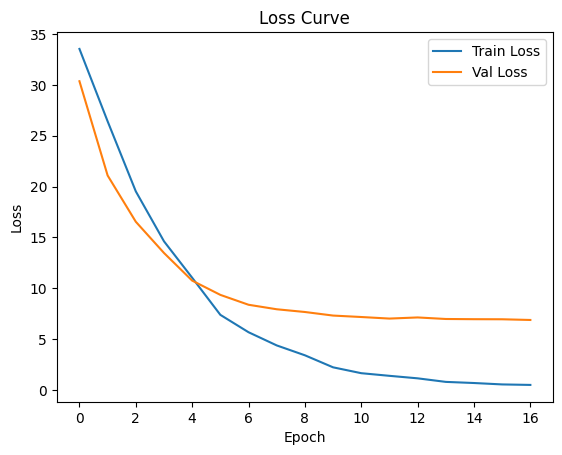

In [32]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

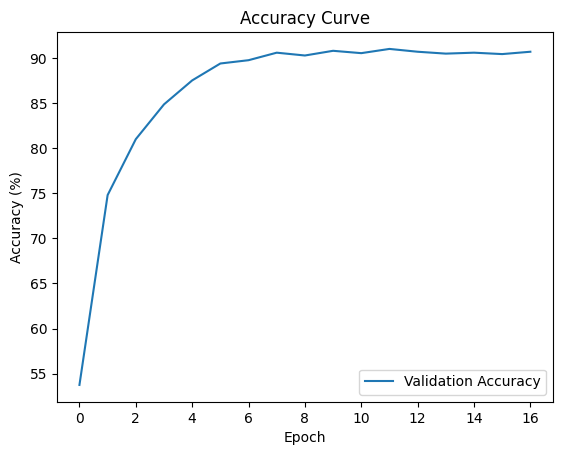

In [33]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    weight = F.normalize(
        criterion.weight,
        dim=1
    )

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        embs = F.normalize(
            model(images),
            dim=1
        )

        logits = embs @ weight.T

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [35]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 90.05%
Rank-5 Accuracy : 97.29%
Rank-10 Accuracy: 98.28%
Precision       : 90.86%
Recall          : 90.05%
F1 Score        : 90.01%


In [36]:
torch.save(model.state_dict(), "ECG-Model-Weight")

In [ ]:
model_1 = ECGCNN(emb_dim=512)

model_1.load_state_dict(
    torch.load("ECG-Model-Weight")
)

model_1.to(device)

ECGCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.2, inplace=False)
    (4): AdaptiveAvgPool2d(output_size=(128, 128))
    (5): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.2, inplace=False)
    (9): AdaptiveAvgPool2d(output_size=(64, 64))
    (10): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Conv2d(64, 128, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequ

In [21]:
model_2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_2 = model_2.to(device)
model_2.eval()

print(model_2)
print(summary(model_2, (3, 224, 224)))

dummy_image = torch.randn(1, 3, 224, 224).to(device) 
with torch.no_grad():

    features = model_2(dummy_image)

print("Extracted feature shape:", features.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_pretrain.pth


100%|██████████| 1.13G/1.13G [00:11<00:00, 103MB/s] 


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-23): 24 x NestedTensorBlock(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, element

In [22]:
@torch.no_grad()
def extract_fused_features(loader, model_1, model_2, device):

    model_1.eval()
    model_2.eval()

    features = []
    labels = []

    for images, target in loader:

        images = images.to(device, non_blocking=True)

        f1 = model_1(images)
        f2 = model_2(images)

        f1 = F.normalize(f1, dim=1)
        f2 = F.normalize(f2, dim=1)

        fused = torch.cat([f1, f2], dim=1)

        features.append(fused.cpu())
        labels.append(target)

    features = torch.cat(features, dim=0)
    labels = torch.cat(labels, dim=0)

    return features.numpy(), labels.numpy()

In [23]:
warnings.filterwarnings("ignore")

X_train, y_train = extract_fused_features(
    train_loader,
    model_1,
    model_2,
    device
)

X_val, y_val = extract_fused_features(
    val_loader,
    model_1,
    model_2,
    device
)

X_test, y_test = extract_fused_features(
    test_loader,
    model_1,
    model_2,
    device
)

X_test_unknown, y_test_unknown = extract_fused_features(
   unknown_test_loader,
    model_1,
    model_2,
    device
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Test(unknown) :", X_test_unknown.shape, y_test_unknown.shape)

Train: (7926, 1536) (7926,)
Val  : (1920, 1536) (1920,)
Test : (1920, 1536) (1920,)
Test(unknown) : (3972, 1536) (3972,)


In [24]:
X_train_tensor = torch.from_numpy(X_train).float()
y_train_tensor = torch.from_numpy(y_train).long()

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

X_val_tensor = torch.from_numpy(X_val).float()
y_val_tensor = torch.from_numpy(y_val).long()

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

X_test_tensor = torch.from_numpy(X_test).float()
y_test_tensor = torch.from_numpy(y_test).long()

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

X_test_unknown_tensor = torch.from_numpy(X_test_unknown).float()
y_test_unknown_tensor = torch.from_numpy(y_test_unknown).long()

unknown_test_dataset = TensorDataset(
    X_test_unknown_tensor,
    y_test_unknown_tensor
)

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X_train_ml = normalize(X_train)
X_val_ml = normalize(X_val)
X_test_ml = normalize(X_test)

pipeline = make_pipeline(

    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),

    StandardScaler(),

    SVC(
        kernel='rbf',
        probability=True
    )
)

pipeline.fit(X_train_ml, y_train)

val_pred = pipeline.predict(X_val_ml)

val_acc = accuracy_score(
    y_val,
    val_pred
)

print("Validation Accuracy:", val_acc)

y_pred = pipeline.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9104166666666667
Accuracy  : 0.9021
Precision : 0.9123
Recall    : 0.9021
F1-Score  : 0.9020


In [26]:
from sklearn.svm import LinearSVC

model = make_pipeline(
    SelectKBest(
        score_func=mutual_info_classif,
        k=512
    ),
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight='balanced',
        max_iter=10000
    )
)

model.fit(X_train_ml, y_train)

val_pred = model.predict(X_val_ml)
val_acc = accuracy_score(y_val, val_pred)

print("Validation Accuracy:", val_acc)

y_pred = model.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Validation Accuracy: 0.9041666666666667
Accuracy  : 0.9010
Precision : 0.9081
Recall    : 0.9010
F1-Score  : 0.9000


In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine'
)

knn.fit(X_train_ml, y_train)

y_pred = knn.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9016
Precision : 0.9092
Recall    : 0.9016
F1-Score  : 0.9010


In [28]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=5000,
    class_weight='balanced'
)

lr.fit(X_train_ml, y_train)

y_pred = lr.predict(X_test_ml)

acc = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9010
Precision : 0.9092
Recall    : 0.9010
F1-Score  : 0.9006


In [29]:
# ------------------- Train -------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------- Validation -------------------
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Test -------------------
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------- Unknown Test -------------------
unknown_test_loader = DataLoader(
    unknown_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [30]:
class FusionClassifier(nn.Module):

    def __init__(self,
                 input_dim=2048,
                 num_classes=200):

        super().__init__()

        self.features = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True)
        )
        self.classifier = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):

        feat = self.features(x)

        logits = self.classifier(feat)

        return logits, feat

In [31]:
lr = 1e-4
weight_decay = 1e-4
num_classes = 160

model = FusionClassifier(input_dim=1536, num_classes=160).to(device)

print(model)
print(summary(model, (1536,)))


images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

logits, feat = model(images)

print("Logits shape:", logits.shape)
print("Feature shape:", feat.shape)

criterion = nn.CrossEntropyLoss().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=3
)

FusionClassifier(
  (features): Sequential(
    (0): Linear(in_features=1536, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
  )
  (classifier): Linear(in_features=512, out_features=160, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1024]       1,573,888
       BatchNorm1d-2                 [-1, 1024]           2,048
              ReLU-3                 [-1, 1024]               0
           Dropout-4                 [-1, 1024]               0
            Linear-5                  [-1, 512]         524,800
       BatchNorm1d-6         

In [32]:
scaler = torch.amp.GradScaler("cuda")
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, feat = model(features)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    return running_loss / len(loader)

In [33]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits, _ = model(features)
        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy

In [37]:
warnings.filterwarnings("ignore")

train_losses = []
val_losses = []
val_accs = []

num_epochs = 100
early_stopping = EarlyStopping(patience=15, min_delta=1e-4)
best_val_acc = 0.0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}% "
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("--> Best model saved.")

    early_stopping(val_acc)
    if early_stopping.stop:
        print("--> Early stopping triggered.")
        break

Epoch [1/100] Train Loss: 1.9578 | Val Loss: 1.0375 | Val Accuracy: 90.57% 
--> Best model saved.
Epoch [2/100] Train Loss: 0.2817 | Val Loss: 0.6602 | Val Accuracy: 90.94% 
--> Best model saved.
Epoch [3/100] Train Loss: 0.1024 | Val Loss: 0.5582 | Val Accuracy: 90.73% 
Epoch [4/100] Train Loss: 0.0547 | Val Loss: 0.5111 | Val Accuracy: 90.83% 
Epoch [5/100] Train Loss: 0.0339 | Val Loss: 0.4866 | Val Accuracy: 90.68% 
Epoch [6/100] Train Loss: 0.0252 | Val Loss: 0.4723 | Val Accuracy: 90.62% 
Epoch [7/100] Train Loss: 0.0211 | Val Loss: 0.4664 | Val Accuracy: 90.52% 
Epoch [8/100] Train Loss: 0.0175 | Val Loss: 0.4592 | Val Accuracy: 90.68% 
Epoch [9/100] Train Loss: 0.0144 | Val Loss: 0.4529 | Val Accuracy: 90.57% 
Epoch [10/100] Train Loss: 0.0126 | Val Loss: 0.4492 | Val Accuracy: 90.78% 
Epoch [11/100] Train Loss: 0.0115 | Val Loss: 0.4465 | Val Accuracy: 90.52% 
Epoch [12/100] Train Loss: 0.0106 | Val Loss: 0.4456 | Val Accuracy: 90.57% 
Epoch [13/100] Train Loss: 0.0095 | Val L

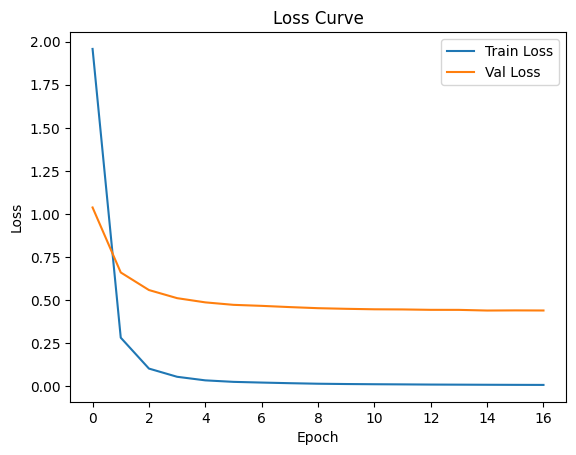

In [38]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

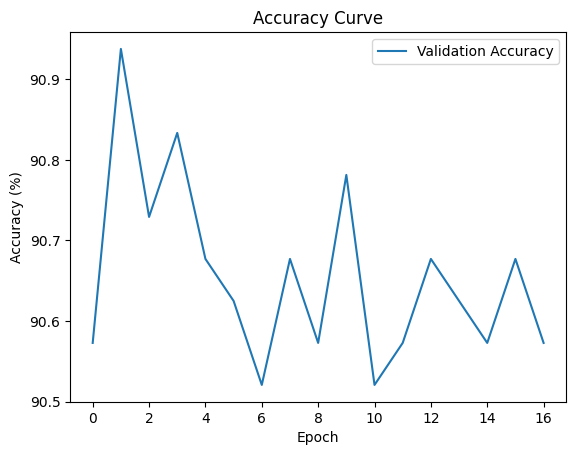

In [39]:
plt.figure()
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [40]:
model.load_state_dict(
    torch.load("best_model.pth")
)

<All keys matched successfully>

In [41]:
@torch.no_grad()
def compute_identification_metrics(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    all_preds = []
    all_labels = []

    rank1 = 0
    rank5 = 0
    rank10 = 0
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        preds = logits.argmax(1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        top5 = logits.topk(
            k=min(5, logits.size(1)),
            dim=1
        ).indices

        top10 = logits.topk(
            k=min(10, logits.size(1)),
            dim=1
        ).indices

        rank1 += (preds == labels).sum().item()

        rank5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        rank10 += (
            top10 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

    return {
        "rank1": 100 * rank1 / total,
        "rank5": 100 * rank5 / total,
        "rank10": 100 * rank10 / total,
        "precision": precision_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "recall": recall_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100,
        "f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ) * 100
    }

In [42]:
@torch.no_grad()
def compute_cmc(
    model,
    loader,
    device,
    max_rank=20
):

    model.eval()

    cmc = np.zeros(max_rank)
    total = 0

    for features, labels in loader:

        features = features.to(device)
        labels = labels.to(device)

        logits, _ = model(features)

        ranks = logits.argsort(
            dim=1,
            descending=True
        )

        for i in range(labels.size(0)):

            pos = (
                ranks[i] == labels[i]
            ).nonzero(
                as_tuple=True
            )[0].item()

            if pos < max_rank:
                cmc[pos:] += 1

        total += labels.size(0)

    return cmc / total

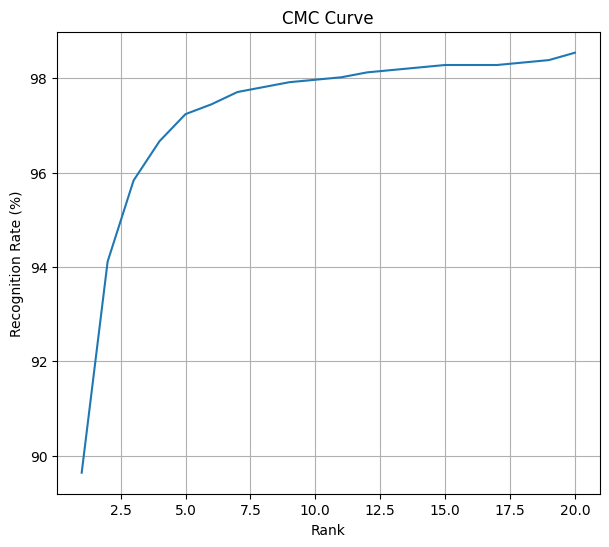

In [43]:
cmc = compute_cmc(
    model,
    test_loader,
    device
)

plt.figure(figsize=(7,6))

plt.plot(
    np.arange(1, len(cmc)+1),
    cmc * 100
)

plt.xlabel("Rank")
plt.ylabel("Recognition Rate (%)")
plt.title("CMC Curve")

plt.grid(True)
plt.show()

In [44]:
id_metrics = compute_identification_metrics(
    model,
    test_loader,
    criterion,
    device
)

print("\n===== Identification =====")
print(f"Rank-1 Accuracy : {id_metrics['rank1']:.2f}%")
print(f"Rank-5 Accuracy : {id_metrics['rank5']:.2f}%")
print(f"Rank-10 Accuracy: {id_metrics['rank10']:.2f}%")
print(f"Precision       : {id_metrics['precision']:.2f}%")
print(f"Recall          : {id_metrics['recall']:.2f}%")
print(f"F1 Score        : {id_metrics['f1']:.2f}%")


===== Identification =====
Rank-1 Accuracy : 89.64%
Rank-5 Accuracy : 97.24%
Rank-10 Accuracy: 97.97%
Precision       : 90.44%
Recall          : 89.64%
F1 Score        : 89.55%
